# Visualisation: plots and the web browser

This tutorial draws the standard population figures of chromatin-tracing data with `uchrom.pl`
(distance matrix, contact map, radius-of-gyration histogram) and then works with the U-Chrom
**web browser** (package `uchrom-browser`, import `uchrom_browser`) from Python: it serves a store
on a local port, queries the server's HTTP API, connects the `Workspace` client and shuts the
server down again.

**Data**: the Takei *et al.* 2021 mESC DNA seqFISH+ traces with their cell table (per-cell RNA
counts) and nascent-RNA spot table (*Nature* 590:344; 4DN `4DNFIHF3JCBY`, `4DNFIFINA2U9`,
`4DNFIJ52NVDV`, FOF-CT; `ds.fetch("takei")` and `ds.fetch("takei_tables")` download them once
from the 4DN data portal), and — if the network is available — the catalog of the public U-Chrom
atlas and one of its stores, read over HTTP.  **Runtime**: under a minute.

In [1]:
import json
import os
import struct
import textwrap
import threading
import time
import urllib.error
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from chromdata import ChromData
import uchrom.datasets as ds
import uchrom.fea as fea
import uchrom.pl as upl

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

CORE = ds.fetch("takei")                       # FOF-CT core table (spots; 4DN, 22 MB; downloaded once)
T = ds.fetch("takei_tables")                   # its cell table and nascent-RNA spot table (4DN)
CELLS, RNA = T / "4DNFIFINA2U9.csv", T / "4DNFIJ52NVDV.csv"

## 1. Load the data and write a store

`from_fofct` reads the core table (one row per spot) together with the cell table (→ `cd.cells`,
RNA counts as `rna.<gene>`) and the nascent-RNA spots (→ `cd.points["rna"]`).  Spots whose trace
id ends in `_-1` were not assigned to an allele; we drop them.  The browser opens
`.chromdata.zarr` stores, so we write one.

In [2]:
raw = ChromData.from_fofct(CORE, cell_table=CELLS, rna_table=RNA)
cd = raw[~raw.spots["trace_id"].astype(str).str.endswith("_-1").to_numpy()]
unit = cd.uns["xyz_unit"]
print(cd)
STORE = OUT / "takei2021_mesc_multiomics.chromdata.zarr"
cd.write(STORE)
print("wrote", STORE)

ChromData: n_spots=314508, n_traces=7626, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  cells:   ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2', 'cytoplasm_area_um2', 'rna.Eef2', 'rna.Auts2', 'rna.Bdnf', 'rna.Clu', 'rna.Cx3cr1', 'rna.Efna5', 'rna.Npy', 'rna.S100b', 'rna.Slc17a7', 'rna.Stmn2', 'rna.Zfp42', 'rna.Myc', 'rna.Ccnd2', 'rna.Mcm2', 'rna.Mki67', 'rna.Sox2', 'rna.Nes', 'rna.Cdk1', 'rna.Mtf2', 'rna.Jade1', 'rna.Cenpa', 'rna.Aurka', 'rna.Plk1', 'rna.Mdm2', 'rna.Aebp2', 'rna.Tet1', 'rna.Nodal', 'rna.Tfcp2l1', 'rna.Tdh', 'rna.Sall4', 'rna.Nanog', 'rna.Esrrb', 'rna.Pou5f1', 'rna.Klf6', 'rna.Ctgf', 'rna.Peg10', 'rna.Myh9', 'rna.Tbx3', 'rna.Otx2', 'rna.Dnmt3a', 'rna.Dnmt3b', 'rna.Lin28a', 'rna.Lin28b', 'rna.Zscan4c', 'rna.Zfp352'] (201 cells)
  points:  {'rna': 3335}
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly', 'fofct_companions', 'cell_spatial']


wrote _out/takei2021_mesc_multiomics.chromdata.zarr


## 2. Plots with `uchrom.pl`

`uchrom.pl` draws matrices and histograms computed by `uchrom.fea`.  Each function returns the
matplotlib figure and takes `ax=` to draw into a panel of your own layout.

**Distance matrix** — the population median distance of every bin pair
(`fea.distance_map`), next to a single trace.  A single trace observes only some of the 60 bins
(blank rows / columns); `observed=False` keeps every bin of the locus so that both matrices share
the same axes.

population: 390 traces | trace 2_45_2_1: 54 of 60 bins


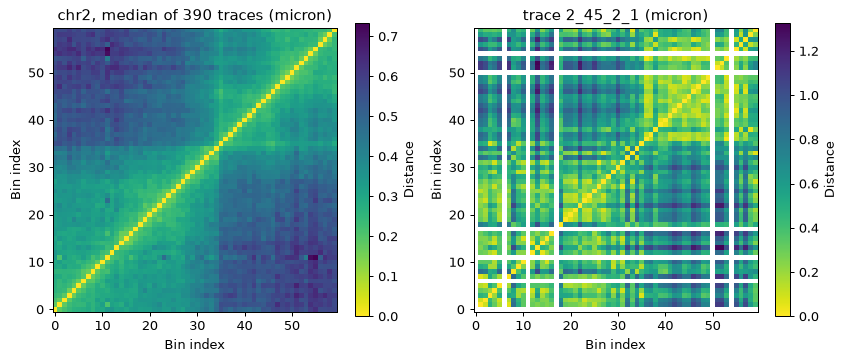

In [3]:
chrom = "chr2"
pop = fea.distance_map(cd, chrom)

c2 = cd.get_chrom(chrom)
spots_per_trace = c2.spots.groupby("trace_id", observed=True).size()
trace = spots_per_trace.idxmax()
one = fea.distance_map(c2.get_trace(trace), chrom, observed=False)
print(f"population: {pop.n_traces} traces | trace {trace}: {int(np.isfinite(np.diag(one.matrix)).sum())} of 60 bins")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
upl.plot_distance_matrix(pop.matrix, title=f"{chrom}, median of {pop.n_traces} traces ({unit})", ax=axes[0])
upl.plot_distance_matrix(one.matrix, title=f"trace {trace} ({unit})", ax=axes[1])
plt.show()

**Contact map** — the fraction of traces in which two bins are closer than a threshold
(`fea.contact_frequency`); here the median distance between adjacent 25-kb bins.

threshold 0.18 micron: adjacent bins in contact in 49% of traces


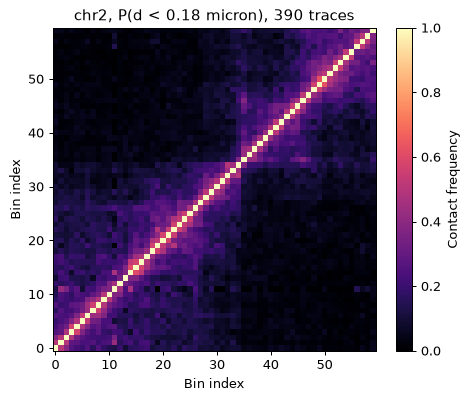

In [4]:
threshold = round(float(np.nanmedian(np.diag(pop.matrix, 1))), 2)
df2 = c2.to_dataframe()
freq, bin_ids, n = fea.contact_frequency(df2, threshold, chrom=chrom)
print(f"threshold {threshold} {unit}: adjacent bins in contact in {np.nanmean(np.diag(freq, 1)):.0%} of traces")
fig = upl.plot_contact_map(freq, title=f"{chrom}, P(d < {threshold} {unit}), {n} traces")
fig.set_size_inches(5.2, 4.3)
plt.show()

**Radius of gyration** — one value per trace (`fea.radius_of_gyration`).  Two loci on shared axes:
the chr7 locus is much less compact than the chr18 locus.

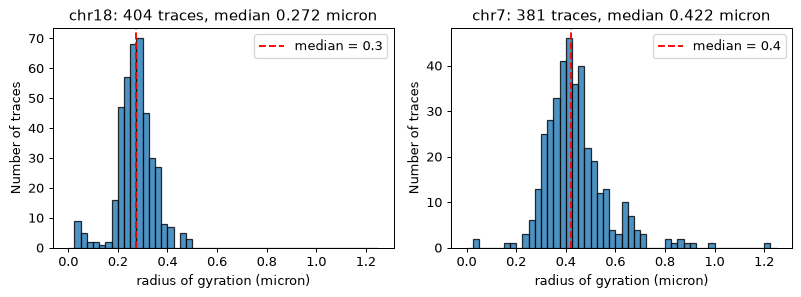

In [5]:
flat = cd.to_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
edges = np.linspace(0, 1.25, 51)                # common bin edges (any `bins` that ax.hist accepts)
for ax, c in zip(axes, ["chr18", "chr7"]):
    rg = fea.radius_of_gyration(flat, chrom=c)
    upl.plot_rg_histogram(rg, bins=edges, title=f"{c}: {rg.notna().sum()} traces, median {rg.median():.3f} {unit}", ax=ax)
    ax.set_xlabel(f"radius of gyration ({unit})")
plt.show()

The legend rounds the median to one decimal; the titles give it exactly.

**3-D structures** — `upl.plot_structure_3d(cd, chrom=..., trace_id=...)` renders traces as tubes
with PyVista, which is an optional dependency (`pip install "u-chrom[plot3d]"`) and is not
installed in this environment, so it is not run here:

```python
plotter = upl.plot_structure_3d(cd, chrom="chr2", trace_id=trace, colour="bin", save_png="trace.png")
```

For a quick look without PyVista, matplotlib's 3-D axes are enough — the trace drawn above,
coloured by genomic position, with equal axis scales:

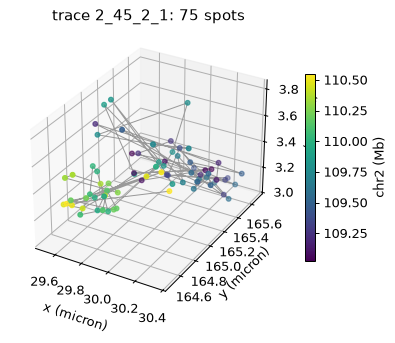

In [6]:
t = c2.get_trace(trace).to_dataframe().sort_values("start")
fig = plt.figure(figsize=(5, 4.5))
ax = fig.add_subplot(projection="3d")
ax.plot(t["x"], t["y"], t["z"], color="0.6", lw=0.8)
sc = ax.scatter(t["x"], t["y"], t["z"], c=t["start"] / 1e6, cmap="viridis", s=14)
ax.set_box_aspect([np.ptp(t[a]) for a in "xyz"])          # true proportions
fig.colorbar(sc, ax=ax, shrink=0.6, label=f"{chrom} (Mb)")
ax.set_xlabel(f"x ({unit})"); ax.set_ylabel(f"y ({unit})"); ax.set_zlabel(f"z ({unit})")
ax.set_title(f"trace {trace}: {len(t)} spots")
plt.show()

## 3. The web browser

The web browser shows a `ChromData` the way the data were taken: cells in their tissue,
structures in 3-D, contact and distance maps, genome tracks and embeddings, linked through the
cells you select.  It is a local FastAPI server plus a single-page app; stores are opened
**backed** (from disk or over HTTP), so only what is on screen is read.

From a terminal:

```bash
pip install uchrom-browser                      # or: pip install "u-chrom[web]"
python -m uchrom_browser data.chromdata.zarr    # = uchrom-browser data.chromdata.zarr; opens http://127.0.0.1:8765/
python -m uchrom_browser a.chromdata.zarr https://…/b.chromdata.zarr --port 9000 --noopen_browser
```

Without a path it opens empty, and the **Open** dialog lists the server's folders and the public
**U-Chrom atlas** (`--atlas URL` to list another one, `--atlas=` for none): single-cell and
spatial Hi-C, Hi-C + RNA and imaging stores hosted at `https://uchrom-atlas-r2.u-science.org` and
read over HTTP on demand.  The same browser runs as a public, hosted service at
**https://uchrom-browser.u-science.org** — open an atlas dataset there without installing anything.

### Serving a store from Python

`uchrom_browser.serve(paths)` is what the command runs; it blocks until interrupted.  In a notebook
we build the same app with `create_app` around a `DatasetStore` and run it with uvicorn in a
background thread on a free port, so that we can shut it down at the end.

In [7]:
import socket

import uvicorn
import uchrom_browser as ub
from uchrom_browser import DatasetStore, create_app


def free_port(host="127.0.0.1"):
    with socket.socket() as s:
        s.bind((host, 0))                       # the OS picks an unused port
        return s.getsockname()[1]


store = DatasetStore()
entry = store.load(STORE)                       # opened backed, as the command does
port = free_port()
app = create_app(store, atlas="https://uchrom-atlas-r2.u-science.org")
server = uvicorn.Server(uvicorn.Config(app, host="127.0.0.1", port=port, log_level="warning"))
thread = threading.Thread(target=server.run, daemon=True)
thread.start()
while not server.started:
    time.sleep(0.05)
URL = f"http://127.0.0.1:{port}"
print(f"serving {entry.name} as dataset {entry.id!r} on port {port} (open {URL}/ in a web browser to see it)")

serving takei2021_mesc_multiomics as dataset 'd1' on port 60907 (open http://127.0.0.1:60907/ in a web browser to see it)


### The HTTP API

The page talks to the server through a small JSON / binary API (documented in
`packages/uchrom-browser/uchrom_browser/API.md`); scripts can use it too.  The dataset summary is
what the page shows first: chromosomes, cell fields (RNA counts, morphology), point sets, tracks.

In [8]:
def get(path):
    with urllib.request.urlopen(URL + path, timeout=120) as r:
        return r.read()


health = json.loads(get("/api/health"))
print({k: health[k] for k in ("status", "version", "chromdata")})
summary = json.loads(get("/api/datasets"))[0]
print({k: summary[k] for k in ("id", "name", "n_spots", "n_bins", "n_traces", "n_cells", "xyz_unit", "trace_mode")})
print("cell fields:", len(summary["cell_fields"]), "e.g.", [f["name"] for f in summary["cell_fields"]][:5])
print("point sets:", [(p["name"], p["n_points"], len(p["labels"])) for p in summary["point_sets"]])
pd.DataFrame(summary["chroms"]).head()

{'status': 'ok', 'version': '0.1.0', 'chromdata': '0.1.0'}
{'id': 'd1', 'name': 'takei2021_mesc_multiomics', 'n_spots': 314508, 'n_bins': 1200, 'n_traces': 7626, 'n_cells': 201, 'xyz_unit': 'micron', 'trace_mode': True}
cell fields: 51 e.g. ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2']
point sets: [('rna', 3335, 23)]


,name,start,end,n_spots,n_traces
0,chr1,135600000,137100000,16191,386
1,chr2,109000000,110575000,13729,390
2,chr3,7675000,9325000,18058,392
3,chr4,89300000,91025000,16067,396
4,chr5,131400000,132900000,14511,382


The statistics behind the Stats and Matrix views are the same as `uchrom.fea`'s.  The per-trace
radius of gyration matches exactly.  The distance matrix differs slightly: when a trace has two
spots in one bin the browser averages them, while `distance_map` keeps the last one; averaging the
duplicates first gives the same matrix.  The matrix arrives as a binary payload (a JSON header,
then `float32` values).

In [9]:
did = summary["id"]
rg_srv = json.loads(get(f"/api/datasets/{did}/stats/rg?chrom={chrom}"))
srv = pd.Series(rg_srv["rg"], index=rg_srv["trace_ids"])
ours = fea.radius_of_gyration(df2, chrom=chrom).rename(index=str)
print(f"Rg of {len(srv)} traces; max |server - fea| = {np.abs(srv - ours.reindex(srv.index)).max():.1e} {unit}")

buf = get(f"/api/datasets/{did}/distance?chrom={chrom}&stat=median")
(h,) = struct.unpack("<I", buf[:4])
header = json.loads(buf[4:4 + h])
mat = np.frombuffer(buf[4 + h:], "<f4").reshape(header["n_rows"], header["n_cols"])
print({k: header[k] for k in ("chrom", "n_rows", "value", "stat", "unit", "n_traces")})

dedup = df2.groupby(["trace_id", "chrom", "start", "end"], observed=True)[["x", "y", "z"]].mean().reset_index()
ref, _, _ = fea.mean_distance_matrix(dedup, chrom=chrom)
dup = df2.duplicated(["trace_id", "start"]).sum()
print(f"{dup} duplicate spots; max |server - distance_map| = {np.nanmax(np.abs(mat - pop.matrix)):.3f} {unit}, "
      f"after averaging duplicates = {np.nanmax(np.abs(mat - ref)):.1e} {unit}")

Rg of 390 traces; max |server - fea| = 1.1e-16 micron
{'chrom': 'chr2', 'n_rows': 60, 'value': 'distance', 'stat': 'median', 'unit': 'micron', 'n_traces': 390}
1177 duplicate spots; max |server - distance_map| = 0.098 micron, after averaging duplicates = 3.0e-08 micron


The server also opens stores by URL — what the Open dialog does for an atlas card.  The catalog
lists every dataset with its URL; opening the smallest one (Stevens *et al.* 2017, single-cell Hi-C
+ 3-D structures of 8 mESCs) reads only its small tables and index over HTTP.  This cell needs the
network and is skipped when it is unavailable.  Without a server, `ds.list_atlas()` gives the same
catalog as a table and `ds.atlas(id)` opens one of its stores backed (see `chromdata_stores`).

In [10]:
def post(path, body):
    req = urllib.request.Request(URL + path, data=json.dumps(body).encode(), method="POST",
                                 headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return json.loads(r.read())


try:
    atlas = json.loads(get("/api/atlas"))
    datasets = pd.DataFrame(atlas["catalog"]["datasets"])
    print(f"atlas {atlas['root']}: {len(datasets)} datasets")
    display(datasets[["id", "organism", "n_cells", "size_mb"]].sort_values("size_mb").head(5))
    small = datasets.sort_values("size_mb").iloc[0]
    t = time.time()
    remote = post("/api/datasets", {"path": small["url"]})
    print(f"opened {remote['name']} over HTTP in {time.time() - t:.1f} s: {remote['n_cells']} cells, "
          f"{remote['n_spots']:,} spots, contact maps {[m['key'] for m in remote['contact_maps']]}")
except (urllib.error.URLError, OSError, KeyError) as exc:
    print("atlas not reachable, skipped:", exc)

atlas https://uchrom-atlas-r2.u-science.org: 22 datasets


,id,organism,n_cells,size_mb
10,stevens2017_mesc,Mus musculus,8,25.8
8,chen2026_cerebellum_adult_20um,Mus musculus,24022,164.8
11,hires_brain,Mus musculus,399,260.9
18,schicar_mouse_cortex,Mus musculus,5313,262.8
20,unic_mouse,Mus musculus,20,270.9


opened stevens2017_mesc over HTTP in 1.0 s: 8 cells, 205,706 spots, contact maps ['bulk', 'per_cell']


### Driving the browser with `uchrom_browser.connect`

`ub.connect(url)` returns a `Workspace`: a client for the **actions** of the open page — read the
researcher's selection, focus cells, set the locus, open and arrange views, colour cells, capture a
view as PNG.  The actions are defined once in `uchrom_browser/ui_tools.json` and become methods of
the workspace.  Without `url`, `connect()` finds the server that `python -m uchrom_browser` started
last (it records its URL in `~/.cache/uchrom/browser.json`; `$UCHROM_BROWSER_URL` overrides).

In [11]:
ws = ub.connect(URL, timeout=10)
print(ws)
for tool in ws.tools():
    print(f"  {tool['name']:<18} {textwrap.shorten(tool['description'], 84)}")
print("connected pages:", ws.pages())

Workspace('http://127.0.0.1:60907')
  describe_workspace What the browser shows now: the active dataset (path, cells, cell fields, [...]
  get_selection      The cells the researcher selected: the current lasso selection, else the [...]
  select_cells       Select cells (like a lasso) and focus them in every view that follows the [...]
  list_groups        Groups available as view scopes: automatic groups (one per value of each [...]
  focus              Focus one cell or one group in every view that follows the focus (the 3-D view [...]
  set_locus          Set the genomic window shared by the Genome, Matrix and Stats views.
  open_view          Open a new view (pane) and make it active. `cells`: 'focus' (default: follow [...]
  show_view          Make a view the active one (in the tabs layout, the one shown).
  close_view         Close a view by its pane id.
  arrange            Lay the views out as tabs, columns, rows or a grid.
  color_by           Colour all cells by a cell field 

Actions are carried out **by the page**: the server forwards each one to the most recently active
browser tab and returns its answer.  This notebook has no page open, so an action fails at once
with a `BrowserError` (HTTP 409); with a page open that does not answer, it fails after `timeout`
seconds (504).

In [12]:
try:
    ws.describe()
except ub.BrowserError as exc:
    print("BrowserError:", exc)

BrowserError: 409: no browser page is connected; open the browser (python -m uchrom_browser …)


With the browser open in a tab (`python -m uchrom_browser data.chromdata.zarr`), a session looks
like this — not run here, since every call needs the page:

```python
ws = ub.connect()                                   # the running server
ws.describe()                                       # dataset, panes, locus, selection
cells = ws.selected_cells()                         # the researcher's lasso / focused group / cell
cd = ws.dataset()                                   # the ChromData the page has open (read in this process)
g = ws.select_cells(cells=cells)["group"]           # register the selection as a group
ws.set_locus(chrom="chr2", start=109_000_000, end=110_600_000)
ws.open_view("genome", cells=g, rows=[{"kind": "distance", "cells": g},
                                      {"kind": "distance", "cells": "all"}])
ws.open_view("stats", stats="rg", compare_groups=[g, "all"])
ws.color_by(field="rna.Nanog")
ws.capture(path="view.png")                         # PNG of the active view
```

`ws.dataset()` asks the page for the open file's path.  Without a page, read the store the server
lists directly — the analysis then runs in this process:

In [13]:
path = json.loads(get("/api/datasets"))[0]["path"]
same = ChromData.read(path, backed=True)
print(os.path.relpath(path), "->", same.n_spots, "spots,", same.n_cells, "cells (backed)")

_out/takei2021_mesc_multiomics.chromdata.zarr -> 314508 spots, 201 cells (backed)


### Shut the server down

In [14]:
server.should_exit = True
thread.join(timeout=10)
try:
    get("/api/health")
    print("still running")
except (urllib.error.URLError, OSError):
    print("server stopped:", not thread.is_alive())

server stopped: True


## Next steps

- `features` — the `uchrom.fea` features behind these plots, and per-locus tracks / peaks /
  annotations that the browser shows as genome tracks.
- `loop_calling`, `tad_calling` — structure calls (stored in `cd.results` / `cd.intervals`) that
  the browser draws as arcs and boxes over the matrices.
- `chromdata_basics`, `import_fofct` — building and writing the stores the browser opens.